# 01 Data Understanding
## 1. Import Libraries

Import the tools used to load, inspect, and visualize the Parkinson’s voice dataset.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load and Preview the Dataset

Load the voice measurements and inspect the first three recordings.

In [2]:
df = pd.read_csv("../data/parkinsons_updrs.data")
df.head(3)

,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014


### Observation

The dataset contains 22 columns. The first three rows are recordings from
the same patient (`subject# = 1`) at different times. `subject#` identifies
the patient, while `motor_UPDRS` is the prediction target for this project.

## 3. Count Recordings and Patients

Count all recordings and use `subject#` to determine how many distinct
patients contributed them.

In [3]:
print("Total recordings:", len(df))
print("Unique patients:", df["subject#"].nunique())

Total recordings: 5875
Unique patients: 42


### Observation

The dataset contains 5,875 voice recordings from 42 distinct patients.
Because patients contribute multiple recordings, all recordings from a
given patient will be kept in the same group during the train/test split.

## 4. Count Recordings per Patient

Compare recording counts across patients to determine whether all patients
contributed the same number of recordings.

In [4]:
recordings_per_patient = df.groupby("subject#").size()

print("Fewest recordings by one patient:", recordings_per_patient.min())
print("Most recordings by one patient:", recordings_per_patient.max())

Fewest recordings by one patient: 101
Most recordings by one patient: 168


### Observation

The number of recordings per patient ranges from 101 to 168. Patients
with more recordings receive more weight when prediction errors are
averaged across recordings.

## 5. Identify the Voice Features

Separate the voice measurements from the patient information, recording
time, and clinical scores. The prediction target is `motor_UPDRS`.

In [5]:
non_voice_columns = [
    "subject#", "age", "sex", "test_time", "motor_UPDRS", "total_UPDRS"
]

voice_features = df.drop(columns=non_voice_columns).columns.tolist()

print("Number of voice features:", len(voice_features))
print("Voice features:", ", ".join(voice_features))

Number of voice features: 16
Voice features: Jitter(%), Jitter(Abs), Jitter:RAP, Jitter:PPQ5, Jitter:DDP, Shimmer, Shimmer(dB), Shimmer:APQ3, Shimmer:APQ5, Shimmer:APQ11, Shimmer:DDA, NHR, HNR, RPDE, DFA, PPE


### Observation

The 16 voice features consist of five jitter measures, six shimmer
measures, and five other acoustic measures. These are the planned model
inputs. `motor_UPDRS` is the prediction target, and `subject#` will be
used to keep each patient's recordings in the same data split.

## 6. Check for Missing Values

Check the voice features, prediction target, and patient identifier for
missing values before preparing the patient-wise split.

In [6]:
columns_to_check = voice_features + ["motor_UPDRS", "subject#"]
missing_counts = df[columns_to_check].isna().sum()

print("Missing values per column:")
print(missing_counts)
print("Total missing values:", missing_counts.sum())

Missing values per column:
Jitter(%)        0
Jitter(Abs)      0
Jitter:RAP       0
Jitter:PPQ5      0
Jitter:DDP       0
Shimmer          0
Shimmer(dB)      0
Shimmer:APQ3     0
Shimmer:APQ5     0
Shimmer:APQ11    0
Shimmer:DDA      0
NHR              0
HNR              0
RPDE             0
DFA              0
PPE              0
motor_UPDRS      0
subject#         0
dtype: int64
Total missing values: 0


### Observation

No missing values were found in the 16 voice features, the `motor_UPDRS`
target, or the `subject#` identifier across all 5,875 recordings.

## 7. Check for Exact Duplicate Rows

Count rows that match an earlier row across all 22 columns.

In [7]:
exact_duplicate_count = df.duplicated(keep="first").sum()
print("Exact duplicate rows:", exact_duplicate_count)

Exact duplicate rows: 0


### Observation

No exact duplicate rows were found across all 22 columns. Repeated
patient IDs represent multiple recordings from the same patient.

## 8. Inspect the Motor UPDRS Target

Summarize the target scores across recordings using the minimum, median,
and maximum values.

In [8]:
target_summary = df["motor_UPDRS"].agg(["min", "median", "max"])
print(target_summary)

min        5.0377
median    20.8710
max       39.5110
Name: motor_UPDRS, dtype: float64


### Observation

Across 5,875 recordings, `motor_UPDRS` ranges from 5.0377 to 39.5110,
with a median of 20.8710. This is the observed range in the dataset,
not the full range of the clinical scale.

## 9. Visualize the Motor UPDRS Distribution

Plot the number of recordings in each score interval to see where
the observed motor UPDRS scores are concentrated.

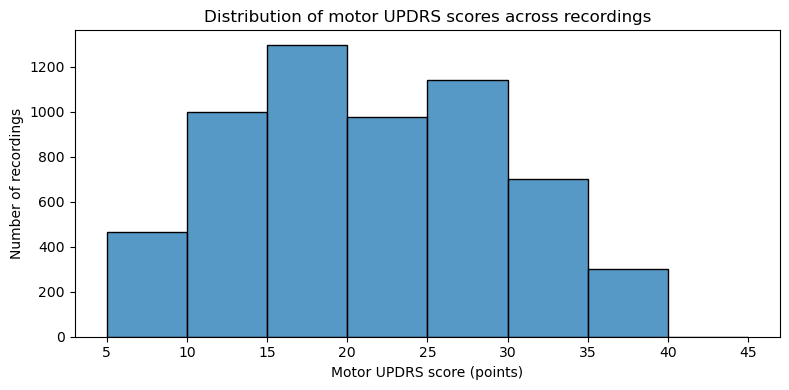

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(data=df, x="motor_UPDRS", bins=range(5, 46, 5), ax=ax)
ax.set(
    title="Distribution of motor UPDRS scores across recordings",
    xlabel="Motor UPDRS score (points)",
    ylabel="Number of recordings",
    xticks=range(5, 46, 5),
)

fig.tight_layout()
plots_dir = Path("../plots")
plots_dir.mkdir(exist_ok=True)
fig.savefig(plots_dir / "motor_updrs_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Observation

The 15–<20 point interval contains the most recordings, followed by the
25–<30 point interval. The histogram counts recordings rather than
unique patients.

## 10. Findings and Baseline Plan

The dataset contains 5,875 recordings from 42 patients, with 101 to 168
recordings per patient. No missing values were found in the 16 voice
features, the target, or the patient identifier. No exact duplicate rows
were found.

The baseline experiment will use the 16 voice features to estimate
`motor_UPDRS`. We will use `subject#` only to assign patients to data
splits, keeping each patient's recordings together. Neither `subject#`
nor `total_UPDRS` will be used as a predictor.